In [1]:
# Applied ML 360° – Day 02 Lab (Climate Applications)

In [3]:
import os
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

In [5]:
# Read the data from the CSV file into a DataFrame
try:
    df = pd.read_csv('climate_data.csv')
    print("Data loaded from 'climate_data.csv'")
    print("\nDataFrame head:\n", df.head())
except FileNotFoundError:
    print("Error: 'climate_data.csv' not found.")
except Exception as e:
    print(f"Error loading data from CSV: {e}")

Data loaded from 'climate_data.csv'

DataFrame head:
                          date       pm25       temp   humidity  wind_speed  \
0  2023-08-29 03:03:28.242730  12.483571  15.587536  72.757576    7.881881   
1  2023-08-30 03:03:28.242730  10.656437  12.237015  62.140492    5.590777   
2  2023-08-31 03:03:28.242730  15.888450  16.568974  72.530318    7.854289   
3  2023-09-01 03:03:28.242730  21.478371  10.408446  66.348089    7.984458   
4  2023-09-02 03:03:28.242730  13.776994  18.775491  69.276402    7.135168   

   rainfall  
0       0.0  
1       0.0  
2       0.0  
3       0.0  
4       0.0  


DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        730 non-null    object 
 1   pm25        730 non-null    float64
 2   temp        730 non-null    float64
 3   humidity    730 non-null    float64
 4   wind_speed  730 non-null    float64
 5   rainfall    730 non-null    float64
dtypes: float64(5), object(1)
memory usage: 34.3+ KB

Descriptive Statistics:


,pm25,temp,humidity,wind_speed,rainfall
count,730.000000,730.000000,730.000000,730.000000,730.000000
mean,28.200740,15.312995,60.160744,6.529338,0.409682
std,12.931175,7.710710,17.083200,0.866926,1.334596
min,-12.773152,-2.494309,12.266320,5.000035,0.000000
25%,18.571429,8.869192,46.725568,5.763897,0.000000
50%,27.752778,15.407441,59.859282,6.590272,0.000000
75%,38.046937,21.901398,72.746049,7.254636,0.000000
max,62.122510,31.895861,104.951514,7.996678,4.997789



Missing Values:


,0
date,0
pm25,0
temp,0
humidity,0
wind_speed,0
rainfall,0


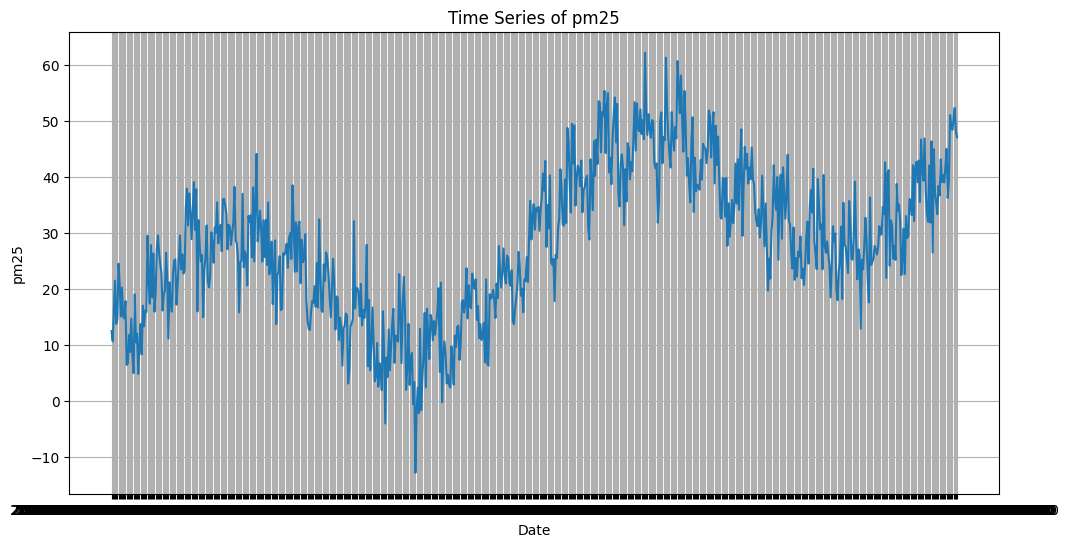

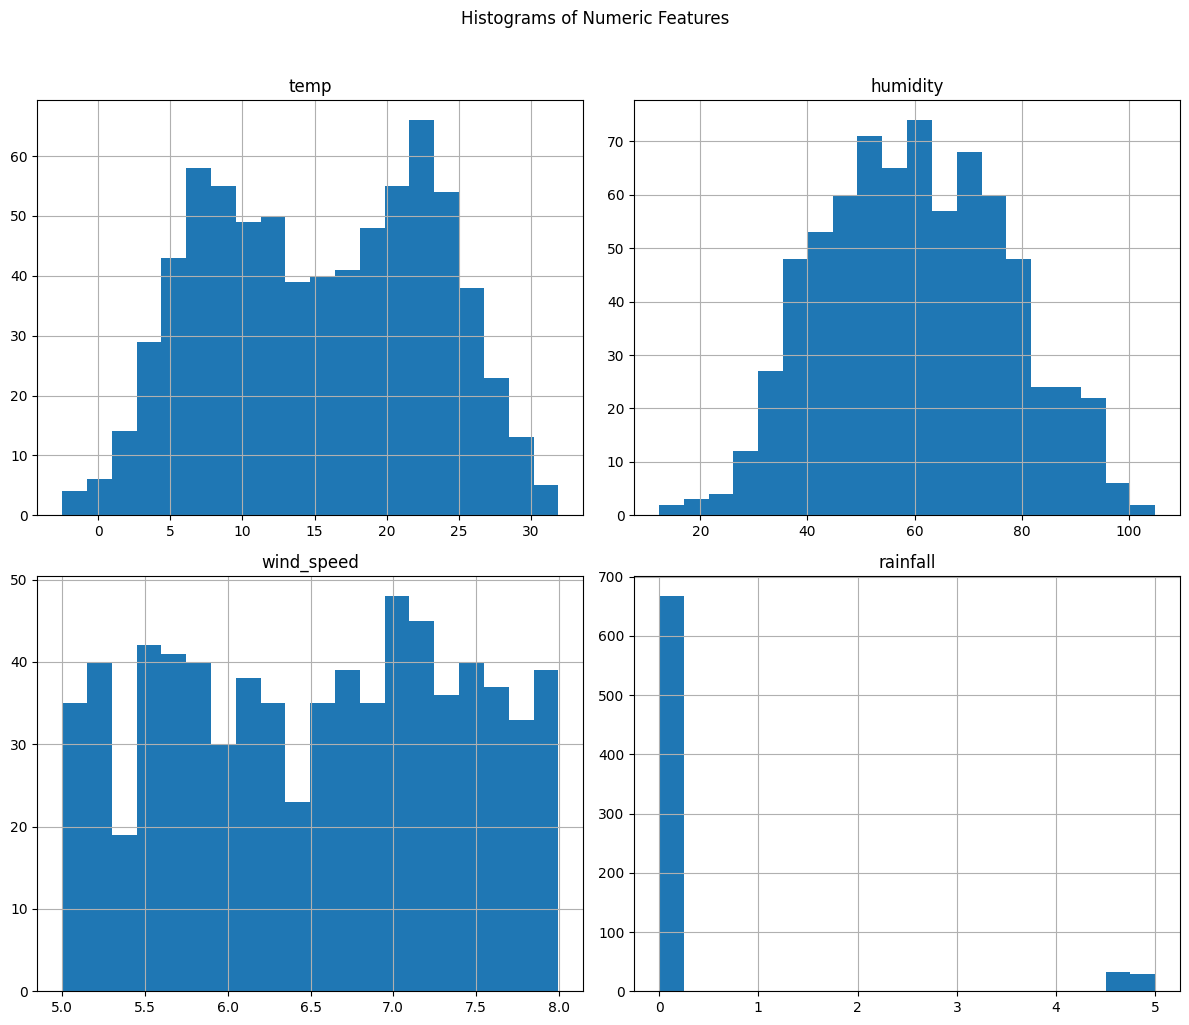

In [9]:
import matplotlib.pyplot as plt

# Show dataframe information
print("DataFrame Info:")
df.info()

# Show descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe())

# Show missing values
print("\nMissing Values:")
display(df.isnull().sum())

# Identify the target variable based on available columns
target_variable = None
if 'traffic_pred' in df.columns:
    target_variable = 'traffic_pred'
elif 'cnt' in df.columns:
    target_variable = 'cnt'
elif 'pm25' in df.columns:
    target_variable = 'pm25'
elif 'temp_anomaly' in df.columns:
    target_variable = 'temp_anomaly'
elif 'Daily minimum temperatures' in df.columns:
    target_variable = 'Daily minimum temperatures'
elif 'Global_Mean_Anomaly' in df.columns:
    target_variable = 'Global_Mean_Anomaly'


# Identify the date column if it exists
date_column = None
if 'date' in df.columns:
    date_column = 'date'
elif 'Date' in df.columns:
    date_column = 'Date'


if target_variable:
    # Plot time series of the target variable ONLY if a date column exists
    if date_column:
        plt.figure(figsize=(12, 6))
        plt.plot(df[date_column], df[target_variable])
        plt.title(f'Time Series of {target_variable}')
        plt.xlabel('Date')
        plt.ylabel(target_variable)
        plt.grid(True)
        plt.show()
    else:
        print("\nNo date column found for time series plotting.")


    # Plot histograms of numeric features
    numeric_features = df.select_dtypes(include=np.number).columns.tolist()
    if target_variable in numeric_features:
        numeric_features.remove(target_variable) # Exclude target from histogram plots

    if numeric_features:
        df[numeric_features].hist(figsize=(12, 10), bins=20)
        plt.suptitle('Histograms of Numeric Features', y=1.02)
        plt.tight_layout()
        plt.show()
else:
    print("\nCould not identify target variable . Skipping plots.")

Handling Missing Data

In [10]:
# Handle missing values
# Use interpolation for short gaps
# df.interpolate(method='linear', inplace=True)

# Use forward and backward fill for any remaining NaNs at the edges
df.ffill(inplace=True)
# df.fillna(method='bfill', inplace=True)

# Re-check missing values
print("\nMissing Values after handling:")
display(df.isnull().sum())


Missing Values after handling:


/tmp/ipython-input-2864254882.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill', inplace=True)


,0
date,0
pm25,0
temp,0
humidity,0
wind_speed,0
rainfall,0


Feature Engineering

In [12]:
# Create lag and rolling features based on the target variable

# Identify the target variable
target_variable = None
if 'pm25' in df.columns:
    target_variable = 'pm25'
elif 'temp_anomaly' in df.columns:
    target_variable = 'temp_anomaly'

if target_variable == 'pm25':
    print("Creating lag and rolling features for pm25.")
    # Create lag features for pm25
    df['pm25_lag_1'] = df['pm25'].shift(1)
    df['pm25_lag_7'] = df['pm25'].shift(7)

    # Create rolling mean feature for pm25
    df['pm25_rolling_7'] = df['pm25'].rolling(window=7).mean()

elif target_variable == 'Daily minimum temperatures':
    print("Creating lag and rolling features for temp_anomaly.")
    # Create lag feature for temp_anomaly
    df['temp_anomaly_lag_1'] = df['temp_anomaly'].shift(1)

    # Create rolling mean feature for temp_anomaly
    df['temp_anomaly_rolling_3'] = df['temp_anomaly'].rolling(window=3).mean()

else:
    print("Could not identify target variable (pm25 or temp_anomaly). Skipping feature engineering.")


# Drop rows with NaNs introduced by feature creation
initial_shape = df.shape
df.dropna(inplace=True)
print(f"\nDropped rows with NaNs. Initial shape: {initial_shape}, New shape: {df.shape}")

Creating lag and rolling features for pm25.

Dropped rows with NaNs. Initial shape: (723, 9), New shape: (716, 9)


Train/Test

In [14]:
# Define target variable
target_variable = None
if 'pm25' in df.columns:
    target_variable = 'pm25'
elif 'temp_anomaly' in df.columns:
    target_variable = 'temp_anomaly'
else:
    raise ValueError("Could not identify target variable (pm25 or temp_anomaly).")

# Define features (all columns except the target)
features = [col for col in df.columns if col != target_variable]

# Separate features and target
X = df[features]
y = df[target_variable]

# Determine the split point (80% for training, 20% for testing)
split_index = int(len(df) * 0.8)

# Split data sequentially
X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

# Print the shapes of the resulting sets
print("Shapes after splitting:")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Shapes after splitting:
X_train shape: (572, 8)
X_test shape: (144, 8)
y_train shape: (572,)
y_test shape: (144,)


Linear Regression Model

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer


# Identify numeric features (excluding the date column if present)
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
# Exclude the 'date' column from features if it exists
features_to_process = [col for col in numeric_features if col != 'date']

# Create preprocessing pipelines for numeric features
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Combine preprocessing steps using ColumnTransformer
# We will explicitly drop the 'date' column
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, features_to_process)
    ],
    remainder='drop' # Drop other columns (like date)
)

# Create the Linear Regression model pipeline
lr_model = Pipeline(steps=[('preprocessor', preprocessor),
                           ('regressor', LinearRegression())])

# Train the Linear Regression model
print("Training Linear Regression model...")
lr_model.fit(X_train, y_train)
print("Linear Regression model trained.")

# Predict on the test data
y_pred_lr = lr_model.predict(X_test)

# Evaluate the model
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("\nLinear Regression Model Evaluation:")
print(f"Mean Absolute Error (MAE): {mae_lr:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_lr:.4f}")
print(f"R-squared (R²): {r2_lr:.4f}")

Training Linear Regression model...
Linear Regression model trained.

Linear Regression Model Evaluation:
Mean Absolute Error (MAE): 4.1525
Root Mean Squared Error (RMSE): 5.0207
R-squared (R²): 0.6120
